# 02. Trics: что действительно может улучшить прогноз

Начинаем с данных, функции ошибки и проверки по времени. Сложная модель полезна, только если её выигрыш переносится на следующий период. Здесь пробуем небольшой набор приёмов, показываем неудачные попытки и сохраняем точный рецепт выбранного решения.

**Задача остаётся прежней:** прогноз количества продаж на один день по паре склад × артикул. История обновляется фактами до вчера. Предсказываем состоявшиеся продажи; скрытый спрос при отсутствии товара в данных не наблюдаем. Официальная метрика и горизонт ещё не предоставлены, локально сравниваем MAE.

Этот ноутбук выполняется **после базовой итерации**, когда существуют `data/processed/train.parquet`, `valid.parquet`, `test.parquet` и дневные таблицы. Исследовательские результаты записываются в `data/artifacts/tricks/`; основной набор из 50 признаков остаётся базой для сравнения.

## План проверки

| Приём | Зачем он здесь | С чем сравниваем |
|---|---|---|
| Более длинная и событийная история | Отличить редкие продажи от затухания товара и уловить недельные привычки | Тот же CatBoost с исходными 50 признаками |
| Больший вес свежих строк | Ассортимент и продажи меняются со временем | Та же модель и признаки, меняются веса обучения |
| Несколько более глубоких деревьев | Проверить, помогают ли более сложные взаимодействия | Та же расширенная история при стандартных деревьях |
| Два этапа: факт продажи и её размер | Отдельно описать множество нулей и объём положительных продаж | Прямой прогноз количества |
| Округление и обнуление малых прогнозов | В обучении количество целочисленное; для MAE маленький положительный прогноз может быть лишним | Тот же прогноз до обработки |
| Смесь с простым средним | Снизить нестабильность разных методов | Лучший необработанный прогноз |

В конце выводим и MAE, и RMSE, и отклонение общего объёма. Улучшение MAE ценой большого недопрогноза — отдельный компромисс, который нужно согласовать с официальной задачей.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs/datasets').is_dir())

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from features.catalog import LABELS, GROUP_LABELS, MODEL_LABELS, feature_label, identifier_label, display_ru
plt.rcParams.update({'date.autoformatter.month':'%m.%Y','date.autoformatter.day':'%d.%m',
                     'date.autoformatter.year':'%Y'})

RAW = ROOT / 'docs/datasets'
PROCESSED = ROOT / 'data/processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option('display.max_columns', 80)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.metrics import mean_absolute_error,mean_squared_error,roc_auc_score,brier_score_loss
OUT=ROOT/'data/artifacts/tricks'; CACHE=PROCESSED/'tricks'; MODELS=ROOT/'data/models/tricks'
for path in [OUT,CACHE,MODELS]: path.mkdir(parents=True,exist_ok=True)
manifest=json.loads((PROCESSED/'feature_manifest.json').read_text())
original_spec=json.loads((ROOT/'data/artifacts/training/catboost_fe_experiment.json').read_text())
BASE_FEATURES=original_spec['features']; CATS=manifest['categorical']+manifest['crosses']
frames={s:pd.read_parquet(PROCESSED/f'{s}.parquet') for s in ['train','valid']}
# Для июльского периода загружаем только ключи и входы, без целевой quantity.
frames['test']=pd.read_parquet(PROCESSED/'test.parquet',columns=['date','pair_id',*BASE_FEATURES])
for f in frames.values():
    for c in CATS: f[c]=f[c].astype('string').fillna('__MISSING__').astype(str)
TUNE_END=frames['valid'].date.min()+pd.Timedelta(days=13)
tune_mask=frames['valid'].date.le(TUNE_END).to_numpy()
check_mask=~tune_mask
assert frames['train'].date.max()<frames['valid'].date.min()
assert frames['valid'].date.max()<frames['test'].date.min()
print('Обучение:',frames['train'].date.min().date(),'—',frames['train'].date.max().date())
print('Выбор настроек:',frames['valid'].date.min().date(),'—',TUNE_END.date())
print('Подтверждение:',(TUNE_END+pd.Timedelta(days=1)).date(),'—',frames['valid'].date.max().date())
print('Июльские метки будут загружены после фиксации рецепта.')

def score(y,pred):
    y=np.asarray(y,dtype='float64'); pred=np.maximum(np.asarray(pred,dtype='float64'),0)
    assert len(y)==len(pred) and np.isfinite(pred).all()
    mass=y.sum()
    return {'MAE':float(np.abs(y-pred).mean()),'WAPE':float(np.abs(y-pred).sum()/mass) if mass>0 else np.nan,
            'RMSE':float(np.sqrt(mean_squared_error(y,pred))),'bias':float((pred-y).mean()),
            'volume_error_pct':float(100*(pred.sum()/mass-1)) if mass>0 else np.nan}

def tune_score(pred):
    return score(frames['valid'].quantity.to_numpy()[tune_mask],np.asarray(pred)[tune_mask])

y=frames['train'].quantity.to_numpy()
integer_share=float(np.isclose(y,np.round(y),atol=1e-6).mean())
assert integer_share==1.0
print(f'Нулей в обучении: {(y==0).mean():.1%}; целочисленных количеств: {integer_share:.1%}')
quarter=frames['train'].groupby(frames['train'].date.dt.to_period('Q'),observed=True).quantity.agg(['size','mean'])
quarter.columns=['Строк обучения','Средние продажи на пару']; display_ru(quarter)

Обучение: 2024-01-29 — 2026-06-05
Выбор настроек: 2026-06-06 — 2026-06-19
Подтверждение: 2026-06-20 — 2026-07-03
Июльские метки будут загружены после фиксации рецепта.
Нулей в обучении: 85.7%; целочисленных количеств: 100.0%


,Строк обучения,Средние продажи на пару
Дата,,
2024Q1,20896,0.193721
2024Q2,41253,0.182508
2024Q3,53492,0.206199
2024Q4,61056,0.213886
2025Q1,63794,0.230147
2025Q2,69187,0.240088
2025Q3,76540,0.276287
2025Q4,78751,0.355475
2026Q1,77550,0.312456


## 1. Проверка метрики и границ

MAE — средняя абсолютная ошибка; её оптимальный прогноз — условная медиана. При частых нулях медиана может равняться нулю, хотя средние продажи положительны. WAPE на одном фиксированном наборе строк отличается от MAE только постоянным знаменателем: их ранжирование моделей совпадает. RMSE сильнее наказывает большие ошибки, а смещение показывает отклонение общего объёма.

У среза «дни без продаж» сумма факта равна нулю, поэтому **WAPE не определена**: записываем пропуск, а не огромное число из деления на маленькую константу. Это особенно важно при чтении ошибок редких товаров.

Для выбора момента остановки деревьев и параметров обработки используем 6–19 июня. Затем фиксируем все рецепты и сравниваем их на 20 июня — 3 июля. Июль не участвует в выборе нового варианта. Но он уже использовался в предыдущих исследованиях, а весь июнь — в старой базовой итерации; это не полностью независимый финальный тест. Следующий строгий шаг — несколько временных окон или новый внешний период.

## 2. История редких продаж

Товар может продаваться редко по разным причинам: он новый, у него невысокий спрос или продажи недавно прекратились. Среднее за семь дней не различает эти ситуации. Добавляем время с последней продажи, длинные окна и поведение в тот же день недели.

**Сглаживание** постепенно уменьшает вес старых наблюдений. Раздельно сглаживаем вероятность ненулевой продажи и её размер. Их произведение — простой прогноз среднего для редкого спроса, по смыслу TSB (Teunter–Syntetos–Babai). Этот прогноз не является оптимальной медианой для MAE; используем его и как ориентир, и как вход бустинга.

| Экспериментальный признак | Смысл |
|---|---|
| Время с последней продажи | Сколько дней прошло с последнего известного положительного количества |
| Сглаженная вероятность продажи | Затухающая доля дней с положительными продажами |
| Сглаженный размер продажи | Размер положительной продажи; обновляется только после продаж |
| Их произведение | Ожидаемый средний объём при редких продажах |
| Средние за 56 и 90 дней | Более длинный уровень продаж |
| Доля дней с продажами за 56 дней | Частота событий отдельно от размера |
| Медиана за 28 дней | Прямой ориентир для MAE |
| Среднее и медиана последних четырёх таких дней недели | Отдельная привычка товара по дням недели |

Все окна заканчиваются вчера, а недельная история — минимум семь дней назад. Подробный словарь находится в [features/TRICKS.md](../features/TRICKS.md).

Добавлено 10 признаков. Проверены недельные окна и отсутствие зависимости от будущих продаж.


,Число значений,Среднее,Стандартное отклонение,Минимум,1%,50%,99%,Максимум,Пропусков = share
Дней с последней продажи,591932.0,24.384,41.128,1.0,1.0,9.000,202.000,842.000,0.013
Сглаженная вероятность продажи,600000.0,0.153,0.206,0.0,0.0,0.070,0.934,1.000,0.000
Сглаженный размер положительной продажи,591932.0,1.292,0.775,1.0,1.0,1.084,3.954,33.515,0.013
Прогноз среднего для редких продаж,600000.0,0.274,0.798,0.0,0.0,0.079,3.085,33.515,0.000
Средние продажи за 56 дней,600000.0,0.261,0.782,0.0,0.0,0.071,3.018,30.518,0.000
Доля дней с продажами за 56 дней,600000.0,0.143,0.193,0.0,0.0,0.071,0.911,1.000,0.000
Средние продажи за 90 дней,600000.0,0.256,0.765,0.0,0.0,0.071,2.933,30.711,0.000
Медиана продаж за 28 дней,600000.0,0.136,0.761,0.0,0.0,0.000,3.000,33.500,0.000
Среднее последних четырёх таких дней недели,596364.0,0.263,0.852,0.0,0.0,0.000,3.250,42.000,0.006
Медиана последних четырёх таких дней недели,596364.0,0.185,0.822,0.0,0.0,0.000,3.000,42.000,0.006


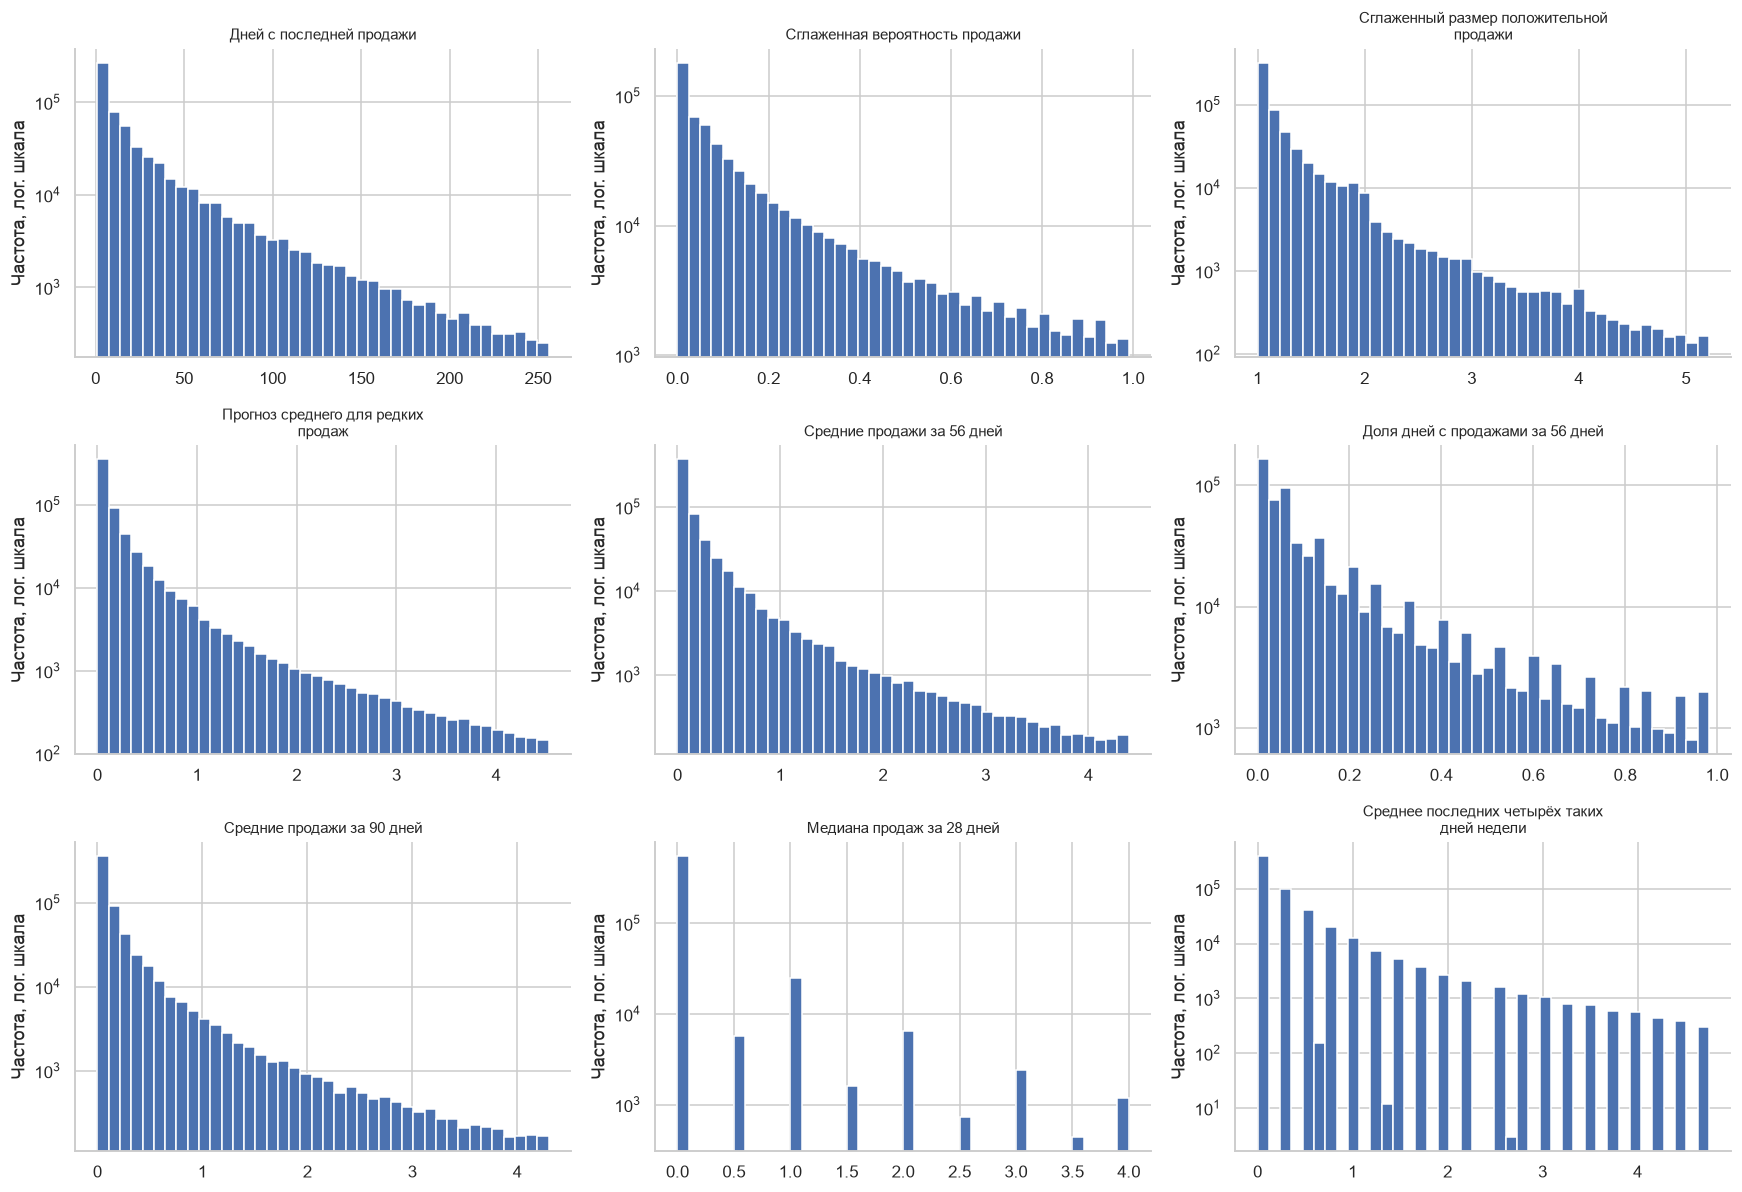

4583

In [2]:
EXTRA_LABELS={
 'tr_days_since_sale':'Дней с последней продажи',
 'tr_sale_prob_28':'Сглаженная вероятность продажи',
 'tr_positive_size_28':'Сглаженный размер положительной продажи',
 'tr_tsb_mean_28':'Прогноз среднего для редких продаж',
 'tr_qty_mean_56':'Средние продажи за 56 дней',
 'tr_sale_share_56':'Доля дней с продажами за 56 дней',
 'tr_qty_mean_90':'Средние продажи за 90 дней',
 'tr_qty_median_28':'Медиана продаж за 28 дней',
 'tr_same_weekday_mean_4':'Среднее последних четырёх таких дней недели',
 'tr_same_weekday_median_4':'Медиана последних четырёх таких дней недели'}
EXTRA=list(EXTRA_LABELS); LABELS.update(EXTRA_LABELS)

def history_features(daily):
    # daily отсортирована по pair_id и дате, дни внутри пары непрерывны.
    pair=daily.pair_id; q=daily.quantity; lag=q.groupby(pair,sort=False).shift(1)
    positive=lag.gt(0).astype('float32').where(lag.notna())
    out=daily[['date','pair_id']].copy()
    last=daily.date.where(q.gt(0)).groupby(pair,sort=False).ffill().groupby(pair,sort=False).shift(1)
    out['tr_days_since_sale']=(daily.date-last).dt.days.astype('float32')
    out['tr_sale_prob_28']=positive.groupby(pair,sort=False).ewm(alpha=2/29,adjust=False,ignore_na=True).mean().to_numpy(dtype='float32')
    out['tr_positive_size_28']=lag.where(lag.gt(0)).groupby(pair,sort=False).ewm(alpha=2/29,adjust=False,ignore_na=True).mean().to_numpy(dtype='float32')
    out['tr_tsb_mean_28']=out.tr_sale_prob_28.fillna(0)*out.tr_positive_size_28.fillna(0)
    for window in [56,90]:
        out[f'tr_qty_mean_{window}']=lag.groupby(pair,sort=False).rolling(window,min_periods=1).mean().to_numpy(dtype='float32')
    out['tr_sale_share_56']=positive.groupby(pair,sort=False).rolling(56,min_periods=1).mean().to_numpy(dtype='float32')
    out['tr_qty_median_28']=lag.groupby(pair,sort=False).rolling(28,min_periods=1).median().to_numpy(dtype='float32')
    dow=daily.date.dt.dayofweek
    weekly_lag=q.groupby([pair,dow],sort=False).shift(1)
    weekly=weekly_lag.groupby([pair,dow],sort=False).rolling(4,min_periods=1)
    for stat in ['mean','median']:
        # Группы дней недели перемешивают исходный индекс: возвращаем порядок строк.
        out[f'tr_same_weekday_{stat}_4']=getattr(weekly,stat)().reset_index(level=[0,1],drop=True).reindex(daily.index).to_numpy(dtype='float32')
    return out

# Восстанавливаем дневной ряд, не пересчитывая основной набор из 50 входов.
pairs=pd.concat([f[['pair_id','date','warehouse_name','article','pair_age_days']] for f in frames.values()],ignore_index=True)
pairs['first_seen']=pairs.date-pd.to_timedelta(pairs.pair_age_days,unit='D')
pairs=pairs.drop_duplicates('pair_id')[['pair_id','warehouse_name','article','first_seen']].sort_values('pair_id').reset_index(drop=True)
assert len(pairs)==manifest['pairs']
first_date=pd.Timestamp('2024-01-01'); last_date=frames['test'].date.max()
start=pairs.first_seen.clip(lower=first_date)
lengths=(last_date-start).dt.days.to_numpy()+1
ids=np.repeat(pairs.pair_id.to_numpy(dtype='int32'),lengths)
dates=np.repeat(start.to_numpy(dtype='datetime64[ns]'),lengths)+np.concatenate([np.arange(n,dtype='timedelta64[D]') for n in lengths])
daily=pd.DataFrame({'pair_id':ids,'date':dates})
sales_daily=pd.read_parquet(PROCESSED/'sales_daily.parquet')
for c in ['warehouse_name','article']:sales_daily[c]=sales_daily[c].astype(str)
events=sales_daily.merge(pairs[['pair_id','warehouse_name','article']],on=['warehouse_name','article'],how='left',validate='many_to_one')
assert events.pair_id.notna().all()
daily=daily.merge(events[['date','pair_id','quantity']],on=['date','pair_id'],how='left',validate='one_to_one').sort_values(['pair_id','date']).reset_index(drop=True)
daily['quantity']=daily.quantity.fillna(0).astype('float32')
assert daily.groupby('pair_id',sort=False).date.diff().dropna().eq(pd.Timedelta(days=1)).all()
extra=history_features(daily); extra['joined']=1
for split,f in list(frames.items()):
    merged=f.merge(extra,on=['date','pair_id'],how='left',validate='one_to_one')
    assert merged[['date','pair_id']].equals(f[['date','pair_id']])
    assert merged.joined.eq(1).all()
    frames[split]=merged.drop(columns='joined')
    frames[split].to_parquet(CACHE/f'{split}_extended.parquet',index=False)
# Независимая проверка недельной истории и зависимости только от прошлого.
one=daily[daily.pair_id.eq(daily.pair_id.iloc[0])].reset_index(drop=True)
probe=history_features(one)
expected=pd.concat([one.quantity.shift(lag) for lag in [7,14,21,28]],axis=1).mean(axis=1)
np.testing.assert_allclose(probe.tr_same_weekday_mean_4,expected,equal_nan=True,rtol=1e-6)
changed=one.copy(); cutoff=len(one)//2; changed.loc[cutoff:,'quantity']=10000
np.testing.assert_allclose(probe[EXTRA].iloc[:cutoff+1],history_features(changed)[EXTRA].iloc[:cutoff+1],equal_nan=True,rtol=1e-6)
assert not np.isinf(frames['train'][EXTRA].to_numpy()).any()
print(f'Добавлено {len(EXTRA)} признаков. Проверены недельные окна и отсутствие зависимости от будущих продаж.')
feature_stats=frames['train'][EXTRA].describe(percentiles=[.01,.5,.99]).T
feature_stats['missing_share']=frames['train'][EXTRA].isna().mean()
feature_stats.to_csv(OUT/'extra_feature_profile.csv'); display_ru(feature_stats.round(3))
fig,axes=plt.subplots(3,3,figsize=(16,11))
for ax,c in zip(axes.ravel(),EXTRA[:9]):
    v=frames['train'][c].dropna(); v=v[v.le(v.quantile(.995))]
    ax.hist(v,bins=40,log=True); ax.set_title(feature_label(c,width=32),fontsize=10); ax.set_ylabel('Частота, лог. шкала')
plt.tight_layout(); plt.savefig(OUT/'01_new_history_features.png',dpi=160,bbox_inches='tight'); plt.show()
del daily,extra,events,sales_daily
import gc; gc.collect()

## 3. Прямой бустинг: меняем по одному условию

Контроль — прежние 50 признаков и прежние параметры CatBoost, но ранняя остановка теперь использует только первую половину июня. Поэтому его числа могут отличаться от старого отчёта. С ним сравниваем три изменения:

1. **История:** добавляем десять признаков при тех же параметрах.
2. **Свежесть:** оставляем расширенную историю, уменьшаем вес строк вдвое каждые 180 дней. Даты и веса известны к концу обучения; метки будущих периодов не нужны.
3. **Более глубокие деревья:** та же история, глубина 7 вместо 6, до 450 деревьев вместо 250. Этот шаг проверяет уже сложность модели, а не новые признаки.

Везде используем MAE и одну обучающую выборку. Ранняя остановка выбирает число деревьев на 6–19 июня. Сейчас выводим только качество на этом периоде; подтверждающее окно откроем после фиксации всех вариантов.

In [3]:
PARAMS=dict(original_spec['parameters'])
PARAMS['allow_writing_files']=False
train=frames['train']; valid=frames['valid']; tune=valid.loc[tune_mask]
EXTENDED=BASE_FEATURES+EXTRA
NAMES={'control':'Контроль: 50 признаков','history':'Длинная и событийная история',
       'recent':'История + вес свежих строк','deep':'История + более глубокие деревья',
       'hurdle_mean':'Два этапа: средний объём','hurdle_gate':'Два этапа: порог вероятности',
       'tsb':'Сглаживание редких продаж','postprocess':'Округление и малые прогнозы',
       'blend':'Смесь с недельным средним','inactive':'Правило неактивного товара'}
# Каждый элемент содержит рецепт, а не только число метрики.
registry={}; fitted={}; training_rows=[]
def register(name,pred,recipe,seconds=0):
    pred=np.maximum(np.asarray(pred,dtype='float64'),0)
    assert len(pred)==len(valid) and np.isfinite(pred).all()
    registry[name]={'validation_prediction':pred,'recipe':recipe,'seconds':float(seconds)}
    s=tune_score(pred)
    print(f"{NAMES[name]}: MAE выбора = {s['MAE']:.5f}; время {seconds:.1f} с",flush=True)

def fit_direct(name,columns,overrides=None,recent=False):
    params=dict(PARAMS);params.update(overrides or {})
    weights=None
    if recent:
        age=(train.date.max()-train.date).dt.days.to_numpy()
        weights=np.power(.5,age/180);weights/=weights.mean()
    start=time.perf_counter(); model=CatBoostRegressor(**params)
    model.fit(train[columns],train.quantity,cat_features=CATS,sample_weight=weights,
              eval_set=(tune[columns],tune.quantity),early_stopping_rounds=35,verbose=False)
    seconds=time.perf_counter()-start
    prediction=model.predict(valid[columns])
    fitted[name]={'model':model,'columns':columns}
    recipe={'kind':'direct','name':name,'features':columns,'parameters':params,'weight_half_life_days':180 if recent else None,'trees':model.tree_count_}
    register(name,prediction,recipe,seconds)
    training_rows.append({'name':name,'features':len(columns),'trees':model.tree_count_,'seconds':seconds,
                          'effective_train_rows':float(weights.sum()**2/(weights**2).sum()) if recent else len(train)})

fit_direct('control',BASE_FEATURES)
fit_direct('history',EXTENDED)
fit_direct('recent',EXTENDED,recent=True)
fit_direct('deep',EXTENDED,overrides={'iterations':450,'depth':7,'learning_rate':.05})
pd.DataFrame(training_rows).to_csv(OUT/'training_runs.csv',index=False)

Контроль: 50 признаков: MAE выбора = 0.28383; время 32.1 с


Длинная и событийная история: MAE выбора = 0.28516; время 29.3 с


История + вес свежих строк: MAE выбора = 0.28383; время 35.7 с


История + более глубокие деревья: MAE выбора = 0.28370; время 51.4 с


## 4. Два этапа: событие и размер продажи

Классификатор оценивает вероятность положительных продаж. При обучении не балансируем классы автоматически: это изменило бы смысл вероятности. На положительных обучающих строках строим отдельно прогноз среднего и прогноз медианы количества.

**Вероятность × средний положительный размер** даёт прогноз среднего общего объёма. **Порог вероятности + положительная медиана** — простая попытка уменьшить MAE. Она не является точным вычислением медианы смешанного распределения: для точного решения потребовались бы условные квантили или вероятности конкретных количеств.

Порог выбираем только на 6–19 июня. Размеры обучения и параметры сохраняем. Гарантированного преимущества перед прямым CatBoost у такого разложения нет.

ROC AUC измеряет, насколько хорошо вероятность отделяет дни с продажами от дней без них: 0,5 соответствует случайному порядку, 1 — идеальному. Brier — средний квадрат ошибки вероятности относительно события 0/1; меньше лучше. Они описывают вероятность события, но итоговый прогноз количества по-прежнему выбираем по MAE.

Два этапа: средний объём: MAE выбора = 0.35131; время 32.1 с


Два этапа: порог вероятности: MAE выбора = 0.28415; время 32.1 с


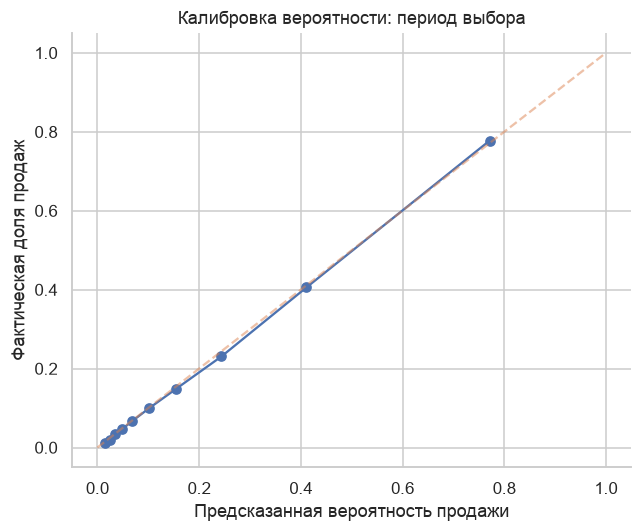

ROC AUC: 0.8698 Brier: 0.095


In [4]:
start=time.perf_counter()
cls_params={'iterations':350,'depth':6,'learning_rate':.07,'loss_function':'Logloss','eval_metric':'Logloss',
            'random_seed':SEED,'thread_count':8,'allow_writing_files':False,'max_ctr_complexity':1,'one_hot_max_size':20}
classifier=CatBoostClassifier(**cls_params)
classifier.fit(train[EXTENDED],train.quantity.gt(0).astype('int8'),cat_features=CATS,
               eval_set=(tune[EXTENDED],tune.quantity.gt(0).astype('int8')),early_stopping_rounds=35,verbose=False)
p_valid=classifier.predict_proba(valid[EXTENDED])[:,1]
positive=train.quantity.gt(0);positive_tune=tune.quantity.gt(0)
size_models={};size_valid={}
for objective in ['RMSE','MAE']:
    params=dict(PARAMS);params.update(iterations=300,loss_function=objective,eval_metric=objective)
    model=CatBoostRegressor(**params)
    model.fit(train.loc[positive,EXTENDED],train.loc[positive,'quantity'],cat_features=CATS,
              eval_set=(tune.loc[positive_tune,EXTENDED],tune.loc[positive_tune,'quantity']),early_stopping_rounds=35,verbose=False)
    size_models[objective]=model
    size_valid[objective]=np.maximum(model.predict(valid[EXTENDED]),0)
hurdle_seconds=time.perf_counter()-start
register('hurdle_mean',p_valid*size_valid['RMSE'],{'kind':'hurdle_mean','features':EXTENDED},hurdle_seconds)
threshold_rows=[]
for threshold in [.35,.4,.45,.5,.55,.6,.65,.7,.75]:
    pred=np.where(p_valid>=threshold,size_valid['MAE'],0)
    threshold_rows.append({'threshold':threshold,**tune_score(pred)})
threshold_table=pd.DataFrame(threshold_rows)
threshold=float(threshold_table.loc[threshold_table.MAE.idxmin(),'threshold'])
register('hurdle_gate',np.where(p_valid>=threshold,size_valid['MAE'],0),
         {'kind':'hurdle_gate','features':EXTENDED,'threshold':threshold},hurdle_seconds)
threshold_table.to_csv(OUT/'hurdle_thresholds.csv',index=False)
# График калибровки: среди прогнозов около 20% событие должно происходить примерно в 20% случаев.
cal=pd.DataFrame({'probability':p_valid[tune_mask],'event':valid.quantity.to_numpy()[tune_mask]>0})
cal['bin']=pd.qcut(cal.probability,10,duplicates='drop')
calibration=cal.groupby('bin',observed=True).agg(predicted=('probability','mean'),actual=('event','mean'),rows=('event','size'))
calibration.to_csv(OUT/'sale_probability_calibration.csv')
plt.figure(figsize=(6,5));plt.plot(calibration.predicted,calibration.actual,'o-');plt.plot([0,1],[0,1],'--',alpha=.5)
plt.xlabel('Предсказанная вероятность продажи');plt.ylabel('Фактическая доля продаж');plt.title('Калибровка вероятности: период выбора')
plt.tight_layout();plt.savefig(OUT/'02_sale_probability.png',dpi=160,bbox_inches='tight');plt.show()
print('ROC AUC:',round(roc_auc_score(cal.event,cal.probability),4),'Brier:',round(brier_score_loss(cal.event,cal.probability),4))

## 5. Обработка прогнозов и смешивание

На целочисленной цели проверяем округление и обнуление небольших прогнозов. Это отдельный вариант: на MAE округление может помочь, но не обязано. При дробных количествах математическое основание такого приёма ослабевает.

Берём лучшую прямую модель **по периоду выбора**, затем проверяем небольшой заранее заданный набор масштабов и порогов. Аналогично подбираем смесь с недельным средним и простое правило для пары, у которой последние 28 дней не было продаж. Остаток сам по себе не используем как запрет продаж: в исходных данных есть продажи при неположительном остатке.

In [5]:
register('tsb',valid.tr_tsb_mean_28.fillna(0).to_numpy(),{'kind':'tsb','alpha_probability':2/29,'alpha_size':2/29})
raw_names=['control','history','recent','deep']
best_raw=min(raw_names,key=lambda n:tune_score(registry[n]['validation_prediction'])['MAE'])
raw=registry[best_raw]['validation_prediction']

def apply_post(pred,scale,threshold,rounding):
    p=np.maximum(np.asarray(pred)*scale,0)
    p=np.where(p<threshold,0,p)
    return np.rint(p) if rounding else p

post_rows=[]
for scale in [.85,1.0,1.15]:
    for threshold in [0,.25,.5]:
        for rounding in [False,True]:
            post_rows.append({'scale':scale,'threshold':threshold,'rounding':rounding,
                              **tune_score(apply_post(raw,scale,threshold,rounding))})
post_table=pd.DataFrame(post_rows)
r=post_table.loc[post_table.MAE.idxmin()]
post_recipe={'kind':'postprocess','parent':best_raw,'scale':float(r.scale),'threshold':float(r.threshold),'rounding':bool(r.rounding)}
register('postprocess',apply_post(raw,post_recipe['scale'],post_recipe['threshold'],post_recipe['rounding']),post_recipe)
post_table.to_csv(OUT/'postprocess_grid.csv',index=False)
naive=valid.qty_roll_mean_7.fillna(train.quantity.mean()).to_numpy()
blend_rows=[{'weight_naive':w,**tune_score((1-w)*raw+w*naive)} for w in [0,.1,.25,.5,.75,1.0]]
blend_table=pd.DataFrame(blend_rows);w=float(blend_table.loc[blend_table.MAE.idxmin(),'weight_naive'])
register('blend',(1-w)*raw+w*naive,{'kind':'blend','parent':best_raw,'weight_naive':w})
blend_table.to_csv(OUT/'blend_grid.csv',index=False)
inactive=valid.qty_roll_mean_28.eq(0).to_numpy()
register('inactive',np.where(inactive,0,raw),{'kind':'inactive','parent':best_raw,'condition':'qty_roll_mean_28 == 0'})
# Конфигурации зафиксированы до просмотра подтверждающей половины июня.
frozen={name:{'recipe':item['recipe'],'seconds':item['seconds']} for name,item in registry.items()}
(OUT/'frozen_candidates.json').write_text(json.dumps({'selection_end':str(TUNE_END.date()),'candidates':frozen},ensure_ascii=False,indent=2))
print('Зафиксированы',len(frozen),'вариантов. Базовая модель для обработки:',NAMES[best_raw])

Сглаживание редких продаж: MAE выбора = 0.34286; время 0.0 с


Округление и малые прогнозы: MAE выбора = 0.28189; время 0.0 с


Смесь с недельным средним: MAE выбора = 0.28370; время 0.0 с


Правило неактивного товара: MAE выбора = 0.28370; время 0.0 с


Зафиксированы 10 вариантов. Базовая модель для обработки: История + более глубокие деревья


## 6. Открываем подтверждающий период

Теперь оцениваем все зафиксированные варианты на 20 июня — 3 июля. До этого момента его метрика не использовалась для обучения, настройки порогов или смеси. Выбираем один вариант по MAE подтверждения; если контроль лучше, сохраняем контроль. Это всё ещё выбор среди нескольких попыток, поэтому небольшой выигрыш требует дополнительных временных окон.

Смотрим и дни с продажами, и нулевые дни. У нулевого среза WAPE не определена. Большой выигрыш только на нулях может сопровождаться недопрогнозом общего объёма.

,Вариант,"MAE, шт.","WAPE, доля","RMSE, шт.","Отклонение общего объёма, %","Улучшение к контролю, %"
name,,,,,,
postprocess,Округление и малые прогнозы,0.26468,0.72722,0.88581,-41.36335,1.09951
recent,История + вес свежих строк,0.26676,0.73293,0.87105,-39.35073,0.32287
inactive,Правило неактивного товара,0.26728,0.73434,0.87566,-39.05602,0.13056
deep,История + более глубокие деревья,0.26728,0.73435,0.87566,-39.05518,0.12972
blend,Смесь с недельным средним,0.26728,0.73435,0.87566,-39.05518,0.12972
control,Контроль: 50 признаков,0.26763,0.73530,0.87673,-38.26211,0.00000
История продаж пары,Длинная и событийная история,0.26817,0.73680,0.88674,-39.31959,-0.20359
hurdle_gate,Два этапа: порог вероятности,0.27152,0.74601,0.86892,-26.38823,-1.45566
tsb,Сглаживание редких продаж,0.33252,0.91359,0.84509,1.71938,-24.24625


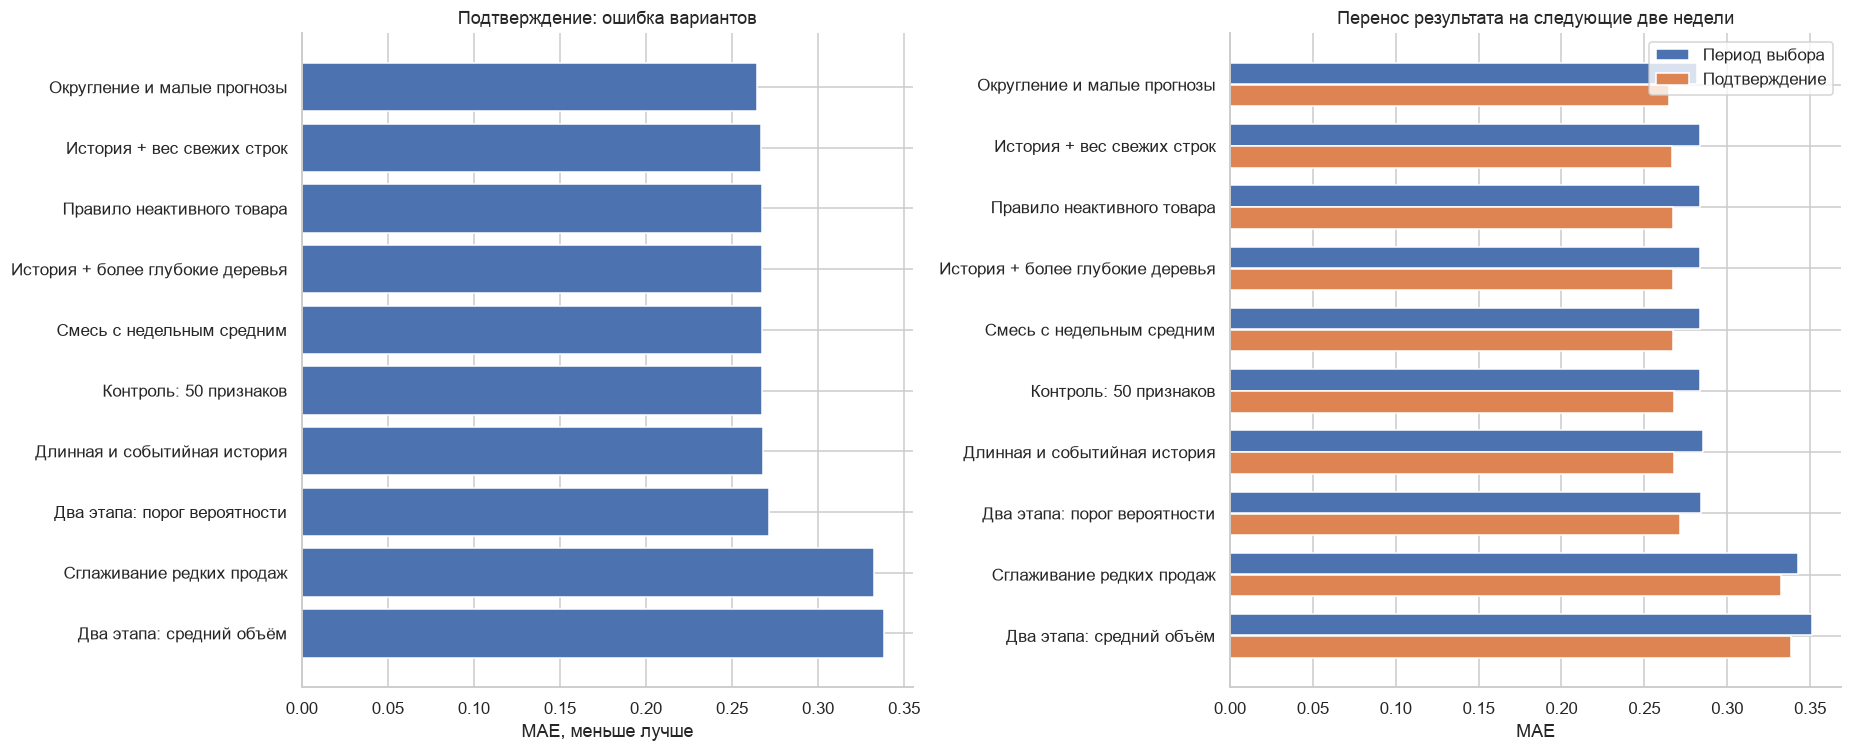

Зафиксирован для июля: Округление и малые прогнозы


In [6]:
validation_rows=[]
for name,item in registry.items():
    pred=item['validation_prediction']
    for period,mask in [('tune',tune_mask),('confirmation',check_mask)]:
        validation_rows.append({'name':name,'label':NAMES[name],'period':period,'rows':int(mask.sum()),
                                **score(valid.quantity.to_numpy()[mask],pred[mask])})
validation_results=pd.DataFrame(validation_rows)
validation_results.to_csv(OUT/'validation_experiments.csv',index=False)
confirmation=validation_results[validation_results.period.eq('confirmation')].set_index('name')
winner=confirmation.MAE.idxmin()
control_mae=float(confirmation.loc['control','MAE'])
confirmation['gain_vs_control_pct']=100*(1-confirmation.MAE/control_mae)
display_ru(confirmation[['label','MAE','WAPE','RMSE','volume_error_pct','gain_vs_control_pct']].sort_values('MAE').rename(columns={
    'label':'Вариант','volume_error_pct':'Отклонение общего объёма, %','gain_vs_control_pct':'Улучшение к контролю, %'}).round(5))
selected={'name':winner,'label':NAMES[winner],'recipe':registry[winner]['recipe'],
          'selected_on':'confirmation MAE, 2026-06-20 — 2026-07-03','tune_end':str(TUNE_END.date()),
          'seed':SEED,'train_rows':len(train),'baseline_features':BASE_FEATURES,'experimental_features':EXTRA}
(OUT/'selected_recipe.json').write_text(json.dumps(selected,ensure_ascii=False,indent=2))
fig,axes=plt.subplots(1,2,figsize=(17,7))
ordered=confirmation.sort_values('MAE')
axes[0].barh(ordered.label,ordered.MAE);axes[0].invert_yaxis();axes[0].set(title='Подтверждение: ошибка вариантов',xlabel='MAE, меньше лучше')
plot=validation_results.pivot(index='name',columns='period',values='MAE').loc[ordered.index]
x=np.arange(len(plot));axes[1].barh(x-.18,plot.tune,height=.35,label='Период выбора');axes[1].barh(x+.18,plot.confirmation,height=.35,label='Подтверждение')
axes[1].set(yticks=x,yticklabels=ordered.label,title='Перенос результата на следующие две недели',xlabel='MAE');axes[1].invert_yaxis();axes[1].legend()
plt.tight_layout();plt.savefig(OUT/'03_validation_comparison.png',dpi=160,bbox_inches='tight');plt.show()
print('Зафиксирован для июля:',NAMES[winner])

## 7. Июльская проверка фиксированного решения

Рецепт уже сохранён. Открываем июльские метки и оцениваем только контроль и выбранный вариант. После этого не меняем настройки по июльским числам. История в признаках июля использует факты предыдущих июльских дней — это допустимо для нашего последовательного однодневного прогноза, но не для прогноза всего месяца из одной даты.

Июль ранее рассматривался в других ноутбуках. Числа ниже — проверка переносимости текущей попытки, а не независимый финальный результат соревнования.

In [7]:
def predict_recipe(recipe,frame):
    kind=recipe['kind']
    if kind=='direct':
        fitted_item=fitted[recipe['name']]
        return np.maximum(fitted_item['model'].predict(frame[fitted_item['columns']]),0)
    if kind in ['hurdle_mean','hurdle_gate']:
        probability=classifier.predict_proba(frame[EXTENDED])[:,1]
        objective='RMSE' if kind=='hurdle_mean' else 'MAE'
        size=np.maximum(size_models[objective].predict(frame[EXTENDED]),0)
        return probability*size if kind=='hurdle_mean' else np.where(probability>=recipe['threshold'],size,0)
    if kind=='tsb':return frame.tr_tsb_mean_28.fillna(0).to_numpy()
    parent=predict_recipe(registry[recipe['parent']]['recipe'],frame)
    if kind=='postprocess':return apply_post(parent,recipe['scale'],recipe['threshold'],recipe['rounding'])
    if kind=='blend':
        w=recipe['weight_naive'];return (1-w)*parent+w*frame.qty_roll_mean_7.fillna(train.quantity.mean()).to_numpy()
    if kind=='inactive':return np.where(frame.qty_roll_mean_28.eq(0),0,parent)
    raise ValueError(kind)

test_target=pd.read_parquet(PROCESSED/'test.parquet',columns=['date','pair_id','quantity'])
assert test_target[['date','pair_id']].equals(frames['test'][['date','pair_id']])
test_rows=[]; test_predictions={}; segment_rows=[]
for name in list(dict.fromkeys(['control',winner])):
    pred=predict_recipe(registry[name]['recipe'],frames['test']);test_predictions[name]=pred
    test_rows.append({'name':name,'label':NAMES[name],**score(test_target.quantity,pred)})
    for segment,mask in [('Все дни',np.ones(len(pred),dtype=bool)),('Дни без продаж',test_target.quantity.eq(0).to_numpy()),
                         ('Дни с продажами',test_target.quantity.gt(0).to_numpy())]:
        segment_rows.append({'name':name,'segment':segment,'rows':int(mask.sum()),**score(test_target.quantity.to_numpy()[mask],pred[mask])})
    saved=test_target.copy();saved['prediction']=pred;saved.to_parquet(CACHE/f'{name}_test_predictions.parquet',index=False)
test_results=pd.DataFrame(test_rows);test_results.to_csv(OUT/'fixed_test_results.csv',index=False)
pd.DataFrame(segment_rows).to_csv(OUT/'test_segments.csv',index=False)
display_ru(test_results[['label','MAE','WAPE','RMSE','volume_error_pct']].rename(columns={'label':'Вариант','volume_error_pct':'Отклонение объёма, %'}).round(5))
# Сохраняем все обученные компоненты, чтобы выбранный рецепт можно было восстановить.
for name,item in fitted.items():
    item['model'].save_model(str(MODELS/f'{name}.cbm'))
classifier.save_model(str(MODELS/'sale_probability.cbm'))
for objective,model in size_models.items():model.save_model(str(MODELS/f'positive_size_{objective}.cbm'))
(MODELS/'selected_recipe.json').write_text(json.dumps(selected,ensure_ascii=False,indent=2))
(MODELS/'components.json').write_text(json.dumps({'direct':{n:{'features':v['columns']} for n,v in fitted.items()},
    'hurdle_features':EXTENDED,'classifier_parameters':cls_params,'fallback_mean':float(train.quantity.mean()),
    'recipes':{n:v['recipe'] for n,v in registry.items()}},ensure_ascii=False,indent=2))

,Вариант,"MAE, шт.","WAPE, доля","RMSE, шт.","Отклонение объёма, %"
0,Контроль: 50 признаков,0.28649,0.71672,0.88589,-39.95281
1,Округление и малые прогнозы,0.28356,0.70940,0.89314,-42.08764


20177

## 8. Вывод: что брать в следующую итерацию

Текст ниже рассчитывается из результатов. Отсутствие выигрыша — полноценный результат: приём требует подтверждения перед переносом в основной процесс. Сохранённый рецепт относится к локальной предварительной задаче.

В текущем прогоне округление улучшило MAE, но усилило недопрогноз объёма. Двухэтапный прогноз среднего улучшил RMSE и точность суммарного объёма при худшем MAE. Значит, выбор функции ошибки определяет, какой прогноз здесь считать сильным.

Следующие приоритеты:

1. Получить официальный горизонт и метрику; привести временную проверку к ним.
2. Проверить выбранный рецепт на нескольких временных окнах и полном пуле около 6 млн обучающих строк вместо выборки 600 тыс.
3. Для прогноза среднего проверить функции потерь счётных моделей Poisson/Tweedie; для MAE — условные квантили или вероятности превышения конкретных количеств.
4. Уточнить смысл остатков и денежных преобразований перед ценовыми признаками или восстановлением потерянного спроса.

Более глубокая модель дошла до ограничения 450 деревьев. Возможность дополнительного обучения стоит проверять на новом временном окне: июльские результаты текущей попытки уже открыты.

In [8]:
confirm_gain=100*(1-confirmation.loc[winner,'MAE']/control_mae)
test_index=test_results.set_index('name')
test_gain=100*(1-test_index.loc[winner,'MAE']/test_index.loc['control','MAE'])
summary=(f"Выбор на подтверждении: **{NAMES[winner]}**. MAE на подтверждении: {control_mae:.4f} → {confirmation.loc[winner,'MAE']:.4f} ({confirm_gain:+.1f}% улучшения). "
         f"На июле: {test_index.loc['control','MAE']:.4f} → {test_index.loc[winner,'MAE']:.4f} ({test_gain:+.1f}% улучшения). "
         f"Отклонение общего объёма выбранного варианта: {test_index.loc[winner,'volume_error_pct']:+.1f}%.")
display(Markdown(summary))
lines=['# Проверка приёмов для прогноза продаж','',summary,'',
       'Обучение: прежние 600 тыс. строк до 2026-06-05. Выбор остановки и параметров: 2026-06-06 — 2026-06-19. Подтверждение и выбор одного рецепта: 2026-06-20 — 2026-07-03. Июль открыт после сохранения рецепта; ранее он использовался в других исследованиях.','',
       '| Вариант | MAE выбора | MAE подтверждения | Изменение к контролю, % |','|---|---:|---:|---:|']
for name,row in confirmation.sort_values('MAE').iterrows():
    tune_mae=float(validation_results[(validation_results.name.eq(name))&validation_results.period.eq('tune')].MAE.iloc[0])
    lines.append(f"| {NAMES[name]} | {tune_mae:.4f} | {row.MAE:.4f} | {row.gain_vs_control_pct:+.1f} |")
lines+=['','Положительное изменение означает уменьшение MAE. Подробные параметры — в `data/artifacts/tricks/selected_recipe.json`, все попытки — в `validation_experiments.csv`. При выборе функции ошибки отдельно учитываем недопрогноз общего объёма.',
        '', 'Десять новых признаков описаны в `features/TRICKS.md`. Они экспериментальные и не добавлены автоматически в основной набор из 50 входов.',
        '', 'Для дальнейшего решения нужны официальная метрика и горизонт, новые временные проверки и сравнение с полным обучающим пулом. На нулевых срезах WAPE не определена и сохраняется пропуском.']
(ROOT/'research/tricks_results.md').write_text('\n'.join(lines)+'\n')
(OUT/'run_summary.md').write_text(summary+'\n')
# Проверки сохранённых рецептов и чисел.
assert (OUT/'selected_recipe.json').exists()
for name in test_index.index:
    p=pd.read_parquet(CACHE/f'{name}_test_predictions.parquet')
    assert p[['date','pair_id']].equals(test_target[['date','pair_id']])
    assert np.isfinite(p.prediction).all() and p.prediction.ge(0).all()
    np.testing.assert_allclose(score(p.quantity,p.prediction)['MAE'],test_index.loc[name,'MAE'])
assert score(np.zeros(3),np.ones(3))['WAPE'] is np.nan or np.isnan(score(np.zeros(3),np.ones(3))['WAPE'])
print('Проверены временные границы, сдвиги новых признаков, ключи прогнозов и сохранённые метрики.')

Выбор на подтверждении: **Округление и малые прогнозы**. MAE на подтверждении: 0.2676 → 0.2647 (+1.1% улучшения). На июле: 0.2865 → 0.2836 (+1.0% улучшения). Отклонение общего объёма выбранного варианта: -42.1%.

Проверены временные границы, сдвиги новых признаков, ключи прогнозов и сохранённые метрики.
